# 03 · Linear regression: what do promotions add to takings?

Two ordinary least squares models on the cleaned data (`data/clean.csv`, from `00_data_cleaning_wz.ipynb`):

| Model | y |
|---|---|
| A | `sausage_roll_takings_gbp` |
| B | `total_shop_takings_gbp` |

Same predictors in both: `store_id`, `day_of_week`, `promotion` and `other_promotion` (all categorical), `temperature_c`, `rain`, `rain_mm`, `home_match_day`, `school_holidays`,
plus two time controls added after the first version of this notebook:
- `list_price`: the regular price of a roll that day (it steps up over the two years, see section 1).
- `month`: month of the year (1-12, categorical), for seasonality.

**How to read a coefficient:** for a categorical variable, the coefficient is the average difference in £ per store-day versus the reference group, holding every other variable fixed.
Reference group: store Kingston Park (`NCL-KP-03`), Monday, January, no promotion, no other promotion.
The **p-value** tests whether the coefficient could plausibly be zero: below 0.05 we call it statistically significant.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.titlelocation": "left", "axes.titlesize": 11, "axes.titleweight": "bold",
})
BLUE = "#2a78d6"

df = pd.read_csv("../data/clean.csv", parse_dates=["date"])
print(f"{len(df):,} rows")

2,180 rows


## 1. Time controls

**List price.** On a day when a store has no roll promotion its average price per roll (takings / rolls sold) is the list price,
and it is the same at every store. So for each date we take it from the stores not running a roll promotion that day.

In [2]:
price = (df.sausage_roll_takings_gbp / df.sausage_rolls_sold).round(2)
df["list_price"] = df.date.map(price[df.promotion == "none"].groupby(df.date).median())
df["month"] = df.date.dt.month  # time of year, treated as categorical in the model

assert df.list_price.notna().all()
df.groupby("list_price").date.agg(first_day="min", last_day="max", days="nunique")

,first_day,last_day,days
list_price,,,
1.200,2024-07-20,2024-07-29,10
1.250,2024-07-30,2025-01-08,163
1.300,2025-01-09,2026-01-07,364
1.350,2026-01-08,2026-07-19,193


## 2. Fit the models

In [3]:
before = (  # the first version of the model, kept to show what the time controls change
    "C(store_id) + C(day_of_week, Treatment('Monday')) + temperature_c + rain + rain_mm"
    " + home_match_day + school_holidays"
    " + C(promotion, Treatment('none')) + C(other_promotion, Treatment('none'))"
)
predictors = before + " + list_price + C(month, Treatment(1))"
targets = {"A: roll takings": "sausage_roll_takings_gbp", "B: shop takings": "total_shop_takings_gbp"}
models = {name: smf.ols(f"{y} ~ {predictors}", data=df).fit() for name, y in targets.items()}
models_before = {name: smf.ols(f"{y} ~ {before}", data=df).fit() for name, y in targets.items()}

pd.DataFrame({
    name: {"observations": int(m.nobs), "R-squared": m.rsquared, "R-squared before time controls": models_before[name].rsquared,
           "avg takings (£)": m.model.endog.mean(), "list_price coef (£ per £1)": m.params["list_price"], "list_price p-value": m.pvalues["list_price"]}
    for name, m in models.items()
})

,A: roll takings,B: shop takings
observations,"2,180.000","2,180.000"
R-squared,0.439,0.462
R-squared before time controls,0.423,0.453
avg takings (£),101.649,"1,544.461"
list_price coef (£ per £1),83.707,193.795
list_price p-value,0.000,0.414


## 3. Coefficients on `promotion` and `other_promotion`

Change in takings per store-day (£) versus a day with no promotion / no other promotion, with the 95% confidence interval and p-value.
`coef before` is the same coefficient from the first version of the model, without list price and month.

In [4]:
def promo_table(m, m_before):
    t = pd.concat([m.params, m.conf_int(), m.pvalues, m_before.params], axis=1)
    t.columns = ["coef (£)", "ci_low", "ci_high", "p-value", "coef before"]
    t = t[t.index.str.contains("promotion")]
    t.index = t.index.str.replace(r"C\((\w+),.*\)\[T\.(.*)\]", r"\1: \2", regex=True)  # "C(promotion, ...)[T.two_for_2]" -> "promotion: two_for_2"
    t["significant (p<0.05)"] = t["p-value"] < 0.05
    return t

tables = {name: promo_table(m, models_before[name]) for name, m in models.items()}
for name, t in tables.items():
    print(name)
    display(t)

A: roll takings


,coef (£),ci_low,ci_high,p-value,coef before,significant (p<0.05)
promotion: 20_percent_off,15.791,8.160,23.422,0.000,10.405,True
promotion: one_pound_week,45.340,34.730,55.950,0.000,46.255,True
promotion: two_for_2,62.633,55.002,70.265,0.000,61.697,True
other_promotion: breakfast_bundle,10.638,3.851,17.426,0.002,8.431,True
other_promotion: coffee_rewards_bonus,13.091,6.086,20.096,0.000,15.233,True
other_promotion: hot_drink_bundle,11.269,3.067,19.471,0.007,3.373,True
other_promotion: summer_lunch_deal,-5.263,-12.764,2.238,0.169,-0.856,False
other_promotion: sweet_treat_offer,-1.983,-10.437,6.472,0.646,-2.964,False


B: shop takings


,coef (£),ci_low,ci_high,p-value,coef before,significant (p<0.05)
promotion: 20_percent_off,72.021,-19.561,163.604,0.123,45.984,False
promotion: one_pound_week,262.678,135.350,390.006,0.000,272.433,True
promotion: two_for_2,56.984,-34.608,148.576,0.223,42.527,False
other_promotion: breakfast_bundle,115.859,34.401,197.317,0.005,67.725,True
other_promotion: coffee_rewards_bonus,174.761,90.693,258.829,0.000,140.420,True
other_promotion: hot_drink_bundle,59.655,-38.781,158.092,0.235,0.760,False
other_promotion: summer_lunch_deal,86.559,-3.458,176.577,0.059,128.050,False
other_promotion: sweet_treat_offer,52.789,-48.677,154.256,0.308,3.000,False


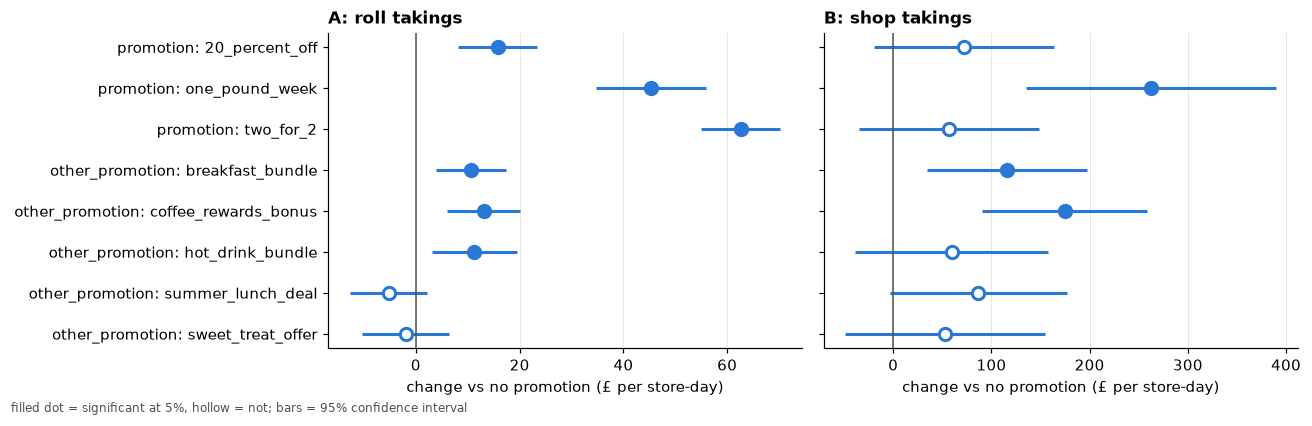

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (name, t) in zip(axes, tables.items()):
    y = range(len(t))[::-1]
    ax.hlines(y, t.ci_low, t.ci_high, color=BLUE, lw=2)
    for yi, (_, r) in zip(y, t.iterrows()):
        # filled dot = significant at 5%, hollow = not
        ax.plot(r["coef (£)"], yi, "o", ms=8, mfc=BLUE if r["p-value"] < 0.05 else "white", mec=BLUE, mew=2)
    ax.axvline(0, color="#52514e", lw=1)
    ax.set_yticks(list(y), t.index)
    ax.set_title(name)
    ax.set_xlabel("change vs no promotion (£ per store-day)")
    ax.grid(axis="y", visible=False)
fig.text(0.01, 0.0, "filled dot = significant at 5%, hollow = not; bars = 95% confidence interval", fontsize=8, color="#52514e")
plt.tight_layout()

## 4. All coefficients (for reference)

In [6]:
pd.concat({name: pd.DataFrame({"coef": m.params, "p": m.pvalues}) for name, m in models.items()}, axis=1)

A: roll takings       B: shop takings      
                                                              coef     p            coef     p
Intercept                                                   -5.912 0.822       1,105.096 0.000
C(store_id)[T.NCL-OQ-01]                                   -24.118 0.000        -244.005 0.000
C(store_id)[T.NCL-SJ-02]                                     5.627 0.000         293.721 0.000
C(day_of_week, Treatment('Monday'))[T.Friday]               19.906 0.000         260.854 0.000
C(day_of_week, Treatment('Monday'))[T.Saturday]             19.254 0.000         176.351 0.000
C(day_of_week, Treatment('Monday'))[T.Sunday]               -2.654 0.167        -137.264 0.000
C(day_of_week, Treatment('Monday'))[T.Thursday]              8.040 0.000         116.662 0.000
C(day_of_week, Treatment('Monday'))[T.Tuesday]               3.043 0.113          47.194 0.040
C(day_of_week, Treatment('Monday'))[T.Wednesday]             2.411 0.211          61.568 0.008
C(promotion, Treatment('none'))[T.20_percent_off]           15.791 0.000          72.021 0.123
C(promotion, Treatment('none'))[T.one_pound_week]           45.340 0.000         262.678 0.000
C(promotion, Treatment('none'))[T.two_for_2]                62.633 0.000          56.984 0.223
C(other_promotion, Treatment('none'))[T.breakfa...          10.638 0.002         115.859 0.005
C(other_promotion, Treatment('none'))[T.coffee_...          13.091 0.000         174.761 0.000
C(other_promotion, Treatment('none'))[T.hot_dri...          11.269 0.007          59.655 0.235
C(other_promotion, Treatment('none'))[T.summer_...          -5.263 0.169          86.559 0.059
C(other_promotion, Treatment('none'))[T.sweet_t...          -1.983 0.646          52.789 0.308
C(month, Treatment(1))[T.2]                                  0.476 0.858          12.543 0.695
C(month, Treatment(1))[T.3]                                 -1.669 0.555          40.435 0.234
C(month, Treatment(1))[T.4]                                  2.267 0.420          98.414 0.004
C(month, Treatment(1))[T.5]                                  2.811 0.286          85.851 0.007
C(month, Treatment(1))[T.6]                                  3.551 0.253          89.067 0.017
C(month, Treatment(1))[T.7]                                  2.669 0.393          93.535 0.013
C(month, Treatment(1))[T.8]                                  0.741 0.841          89.685 0.044
C(month, Treatment(1))[T.9]                                 -1.784 0.625          59.936 0.171
C(month, Treatment(1))[T.10]                                -5.232 0.141          17.198 0.687
C(month, Treatment(1))[T.11]                                -6.435 0.061          -7.233 0.861
C(month, Treatment(1))[T.12]                                -2.193 0.472          -7.426 0.839
temperature_c                                               -0.603 0.012           0.457 0.873
rain                                                        -4.671 0.001         -29.951 0.085
rain_mm                                                     -0.053 0.799          -0.409 0.871
home_match_day                                              27.279 0.000         217.940 0.000
school_holidays                                              4.036 0.014          82.223 0.000
list_price                                                  83.707 0.000         193.795 0.414

## 5. Robustness check

The plain p-values assume the spread of errors is the same everywhere. Takings are much bigger at some stores and on some days,
so we re-run with heteroskedasticity-robust standard errors (`HC3`). If significance at 5% flips for any promotion term, we should be careful.

In [7]:
rows = []
for (name, y), t in zip(targets.items(), tables.values()):
    robust = smf.ols(f"{y} ~ {predictors}", data=df).fit(cov_type="HC3").pvalues
    robust = robust[[i for i in robust.index if "promotion" in i]]
    rows.append(pd.DataFrame({"model": name, "term": t.index, "p-value": t["p-value"].values, "p-value (robust)": robust.values}))
check = pd.concat(rows, ignore_index=True)
check["significance flips"] = (check["p-value"] < 0.05) != (check["p-value (robust)"] < 0.05)
print("terms where significance flips:", int(check["significance flips"].sum()), "of", len(check))
check

terms where significance flips: 1 of 16


,model,term,p-value,p-value (robust),significance flips
0,A: roll takings,promotion: 20_percent_off,0.000,0.000,False
1,A: roll takings,promotion: one_pound_week,0.000,0.000,False
2,A: roll takings,promotion: two_for_2,0.000,0.000,False
3,A: roll takings,other_promotion: breakfast_bundle,0.002,0.003,False
4,A: roll takings,other_promotion: coffee_rewards_bonus,0.000,0.001,False
5,A: roll takings,other_promotion: hot_drink_bundle,0.007,0.003,False
6,A: roll takings,other_promotion: summer_lunch_deal,0.169,0.102,False
7,A: roll takings,other_promotion: sweet_treat_offer,0.646,0.638,False
8,B: shop takings,promotion: 20_percent_off,0.123,0.103,False
9,B: shop takings,promotion: one_pound_week,0.000,0.015,False


## What I found

**Fit:** with list price and month added, the predictors explain 44% of the variation in roll takings (R² 0.44, up from 0.42) and 46% in total shop takings (R² 0.46, up from 0.45).

**What the time controls did**
- **List price:** each extra £1 on the list price adds about £84 of roll takings per store-day (p < 0.001), i.e. about £8 for a 10p rise. It has no clear effect on total shop takings (p = 0.41).
- **Season:** shop takings are about £85-£100 higher from April to August than in January. Roll takings barely vary by month.
- **Roll promotions barely moved.** They were already the clearest result and stay that way.
- **`other_promotion` moved more**, since those offers ran in particular seasons.

**`promotion` (versus a day with no promotion)**

| | Roll takings | Shop takings |
|---|---|---|
| `two_for_2` | **+£63** (p < 0.001) | +£57 (p = 0.22, not significant) |
| `one_pound_week` | **+£45** (p < 0.001) | **+£263** (p < 0.001) |
| `20_percent_off` | **+£16** (p < 0.001) | +£72 (p = 0.12, not significant) |

- All three promotions raise **roll takings** significantly. `two_for_2` and `one_pound_week` add several times more than `20_percent_off` (up from about £10 before the time controls, still small on a ~£100 day).
- Only `one_pound_week` has a significant effect on **total shop takings**. The shop-wide effect of the other two is too noisy to tell apart from zero.
- `two_for_2` and `one_pound_week` are close on roll takings (the confidence intervals overlap), so this model can't separate them on rolls.

**`other_promotion`**
- `coffee_rewards_bonus` (+£13 roll, +£175 shop) and `breakfast_bundle` (+£11 roll, +£116 shop) are significant for both outcomes. `breakfast_bundle` was not significant for shop takings before the time controls.
- `hot_drink_bundle` now lifts roll takings (+£11, p = 0.007); before the time controls it looked like zero, because it ran in a seasonally weak period.
- `summer_lunch_deal` and `sweet_treat_offer` do not clearly move roll takings. `summer_lunch_deal` on shop takings is borderline (+£87, p = 0.059).
- Robust standard errors change one call: `summer_lunch_deal` on shop takings becomes significant (p = 0.039), a borderline result either way.

**Caveats**
- **Few independent periods.** Each roll promotion ran as just three 1-2 week blocks (one per store). Days within a block move together, so the p-values are likely too optimistic.
- `other_promotion` ran in all three stores at the same time, so even with month and list price it is hard to separate from whatever else changed in that window.
- `rain` is just `rain_mm > 0`, so the two overlap and their individual coefficients are not reliable on their own.
- Next step (`04`): do these promotions change takings on the days after they end, and do promotions at other stores affect a store's own takings?